###Name: Sayali Gundawar
###Roll: 21
###Batch/Section: B3-B2
Practical 8

Part A

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [ ]:
df = pd.read_csv('carpurchasing.csv', encoding='latin1')

df

,customer name,customer e-mail,country,gender,age,annual Salary,credit card debt,net worth,car purchase amount
0,Martina Avila,cubilia.Curae.Phasellus@quisaccumsanconvallis.edu,Bulgaria,0,41.851720,62812.09301,11609.380910,238961.2505,35321.45877
1,Harlan Barnes,eu.dolor@diam.co.uk,Belize,0,40.870623,66646.89292,9572.957136,530973.9078,45115.52566
2,Naomi Rodriquez,vulputate.mauris.sagittis@ametconsectetueradip...,Algeria,1,43.152897,53798.55112,11160.355060,638467.1773,42925.70921
3,Jade Cunningham,malesuada@dignissim.com,Cook Islands,1,58.271369,79370.03798,14426.164850,548599.0524,67422.36313
4,Cedric Leach,felis.ullamcorper.viverra@egetmollislectus.net,Brazil,1,57.313749,59729.15130,5358.712177,560304.0671,55915.46248
...,...,...,...,...,...,...,...,...,...
495,Walter,ligula@Cumsociis.ca,Nepal,0,41.462515,71942.40291,6995.902524,541670.1016,48901.44342
496,Vanna,Cum.sociis.natoque@Sedmolestie.edu,Zimbabwe,1,37.642000,56039.49793,12301.456790,360419.0988,31491.41457
497,Pearl,penatibus.et@massanonante.com,Philippines,1,53.943497,68888.77805,10611.606860,764531.3203,64147.28888
498,Nell,Quisque.varius@arcuVivamussit.net,Botswana,1,59.160509,49811.99062,14013.034510,337826.6382,45442.15353


In [ ]:
df.head()

,customer name,customer e-mail,country,gender,age,annual Salary,credit card debt,net worth,car purchase amount
0,Martina Avila,cubilia.Curae.Phasellus@quisaccumsanconvallis.edu,Bulgaria,0,41.851720,62812.09301,11609.380910,238961.2505,35321.45877
1,Harlan Barnes,eu.dolor@diam.co.uk,Belize,0,40.870623,66646.89292,9572.957136,530973.9078,45115.52566
2,Naomi Rodriquez,vulputate.mauris.sagittis@ametconsectetueradip...,Algeria,1,43.152897,53798.55112,11160.355060,638467.1773,42925.70921
3,Jade Cunningham,malesuada@dignissim.com,Cook Islands,1,58.271369,79370.03798,14426.164850,548599.0524,67422.36313
4,Cedric Leach,felis.ullamcorper.viverra@egetmollislectus.net,Brazil,1,57.313749,59729.15130,5358.712177,560304.0671,55915.46248


In [ ]:
df.tail()

,customer name,customer e-mail,country,gender,age,annual Salary,credit card debt,net worth,car purchase amount
495,Walter,ligula@Cumsociis.ca,Nepal,0,41.462515,71942.40291,6995.902524,541670.1016,48901.44342
496,Vanna,Cum.sociis.natoque@Sedmolestie.edu,Zimbabwe,1,37.642000,56039.49793,12301.456790,360419.0988,31491.41457
497,Pearl,penatibus.et@massanonante.com,Philippines,1,53.943497,68888.77805,10611.606860,764531.3203,64147.28888
498,Nell,Quisque.varius@arcuVivamussit.net,Botswana,1,59.160509,49811.99062,14013.034510,337826.6382,45442.15353
499,Marla,Camaron.marla@hotmail.com,marlal,1,46.731152,61370.67766,9391.341628,462946.4924,45107.22566


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   customer name        500 non-null    object 
 1   customer e-mail      500 non-null    object 
 2   country              500 non-null    object 
 3   gender               500 non-null    int64  
 4   age                  500 non-null    float64
 5   annual Salary        500 non-null    float64
 6   credit card debt     500 non-null    float64
 7   net worth            500 non-null    float64
 8   car purchase amount  500 non-null    float64
dtypes: float64(5), int64(1), object(3)
memory usage: 35.3+ KB


In [ ]:
 df.shape

(500, 9)

In [ ]:
#Check Missing Values
print("Missing values:")
print(df.isnull().sum())

Missing values:
customer name          0
customer e-mail        0
country                0
gender                 0
age                    0
annual Salary          0
credit card debt       0
net worth              0
car purchase amount    0
dtype: int64


In [ ]:
#Check Duplicate Records
print("Number of duplicate records:", df.duplicated().sum())

Number of duplicate records: 0


In [ ]:
# Numerical variables
numerical_columns = df.select_dtypes(include=['int64', 'float64']).columns

print("Numerical Variables:")
print(numerical_columns)

Numerical Variables:
Index(['gender', 'age', 'annual Salary', 'credit card debt', 'net worth',
       'car purchase amount'],
      dtype='object')


In [ ]:
# categorical variables
categorical_columns = df.select_dtypes(include=['object']).columns

print("Categorical Variables:")
print(categorical_columns)

Categorical Variables:
Index(['customer name', 'customer e-mail', 'country'], dtype='object')


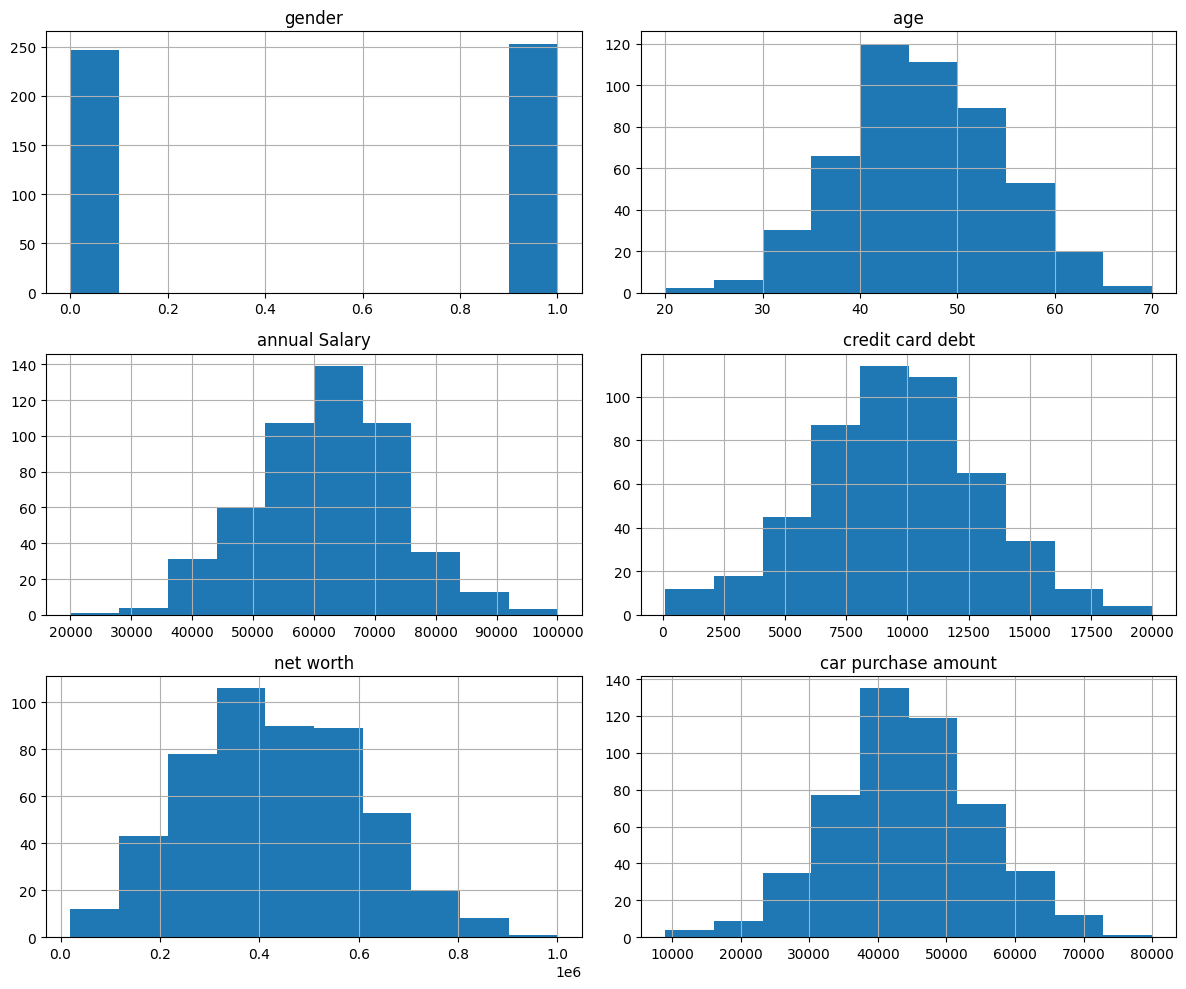

In [ ]:
#Distribution plots
df[numerical_columns].hist(figsize=(12, 10))

plt.tight_layout()
plt.show()

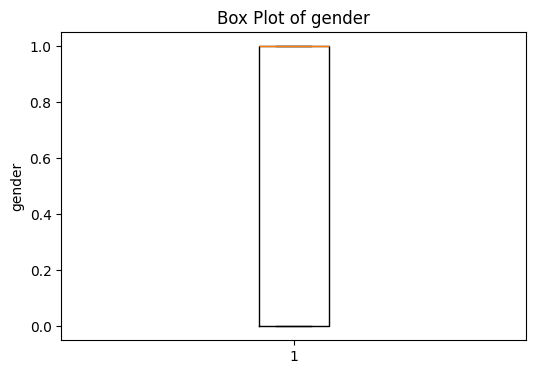

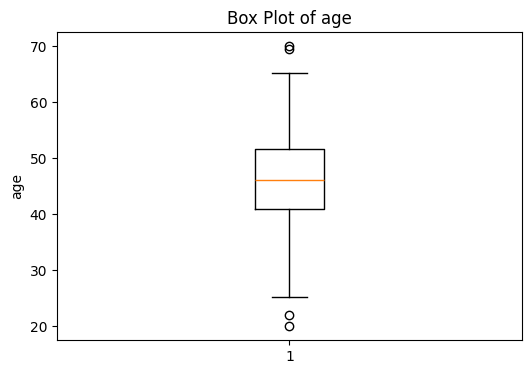

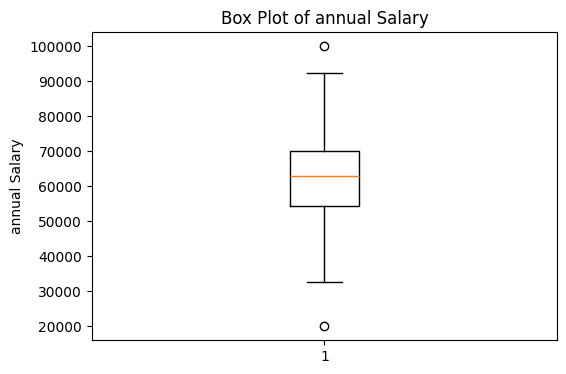

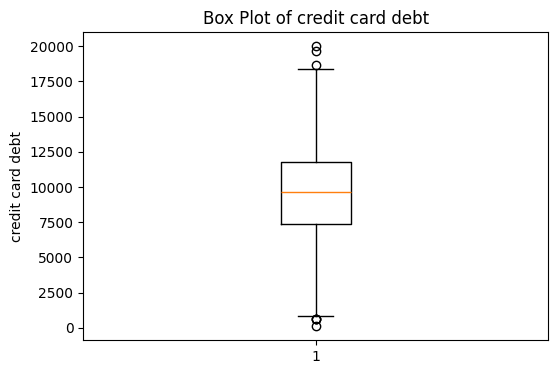

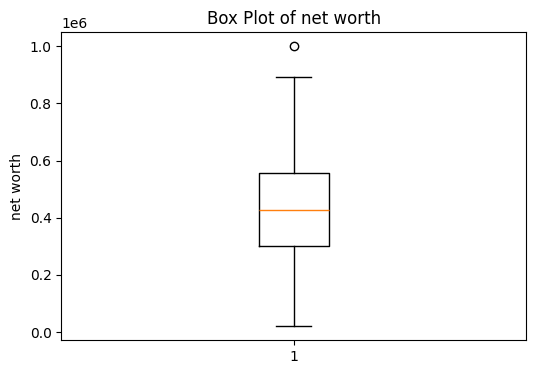

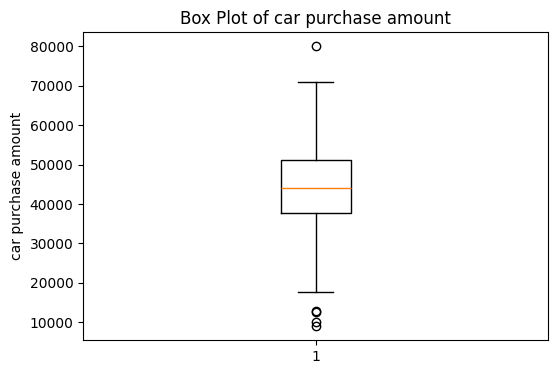

In [ ]:
#Box plots
for column in numerical_columns:
    plt.figure(figsize=(6, 4))
    plt.boxplot(df[column].dropna())
    plt.title("Box Plot of " + column)
    plt.ylabel(column)
    plt.show()

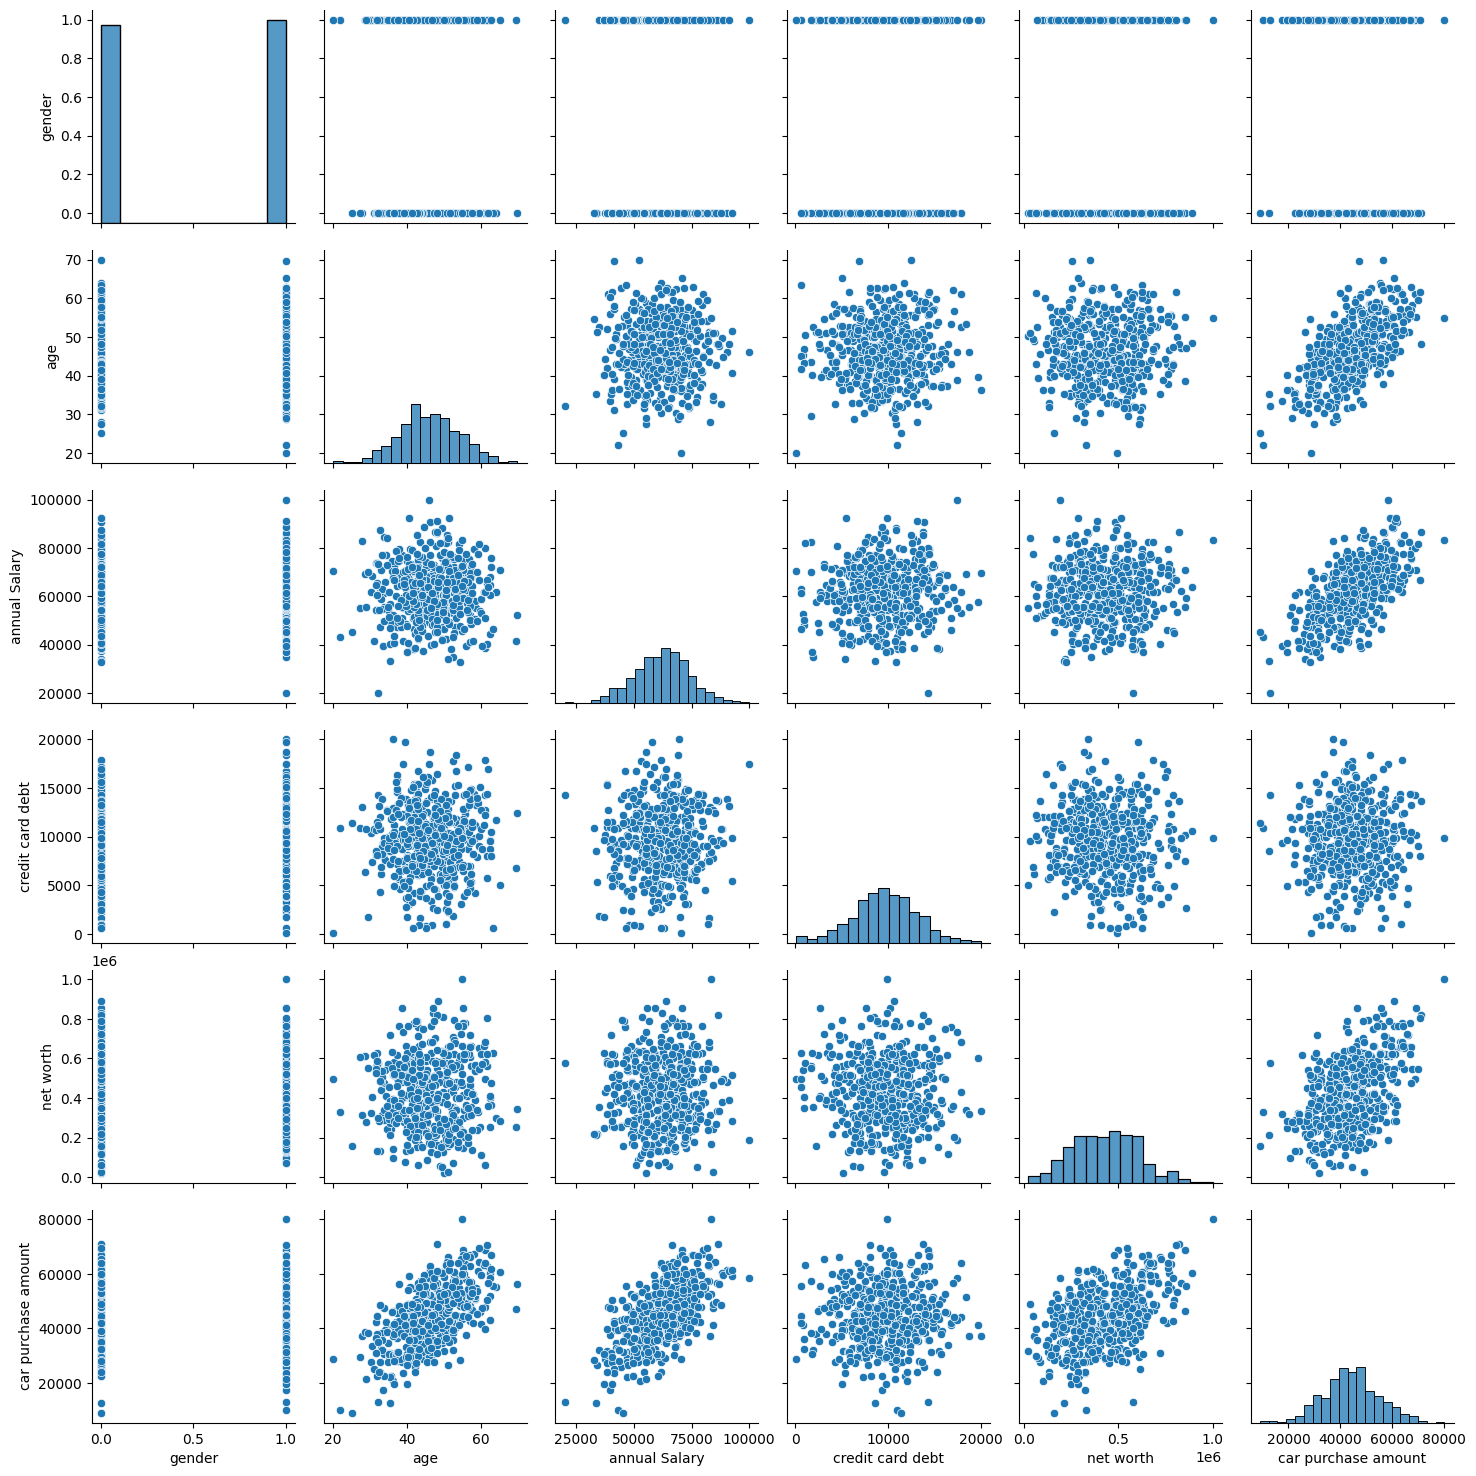

In [ ]:
#Scatter plots
sns.pairplot(df[numerical_columns])
plt.show()

In [ ]:
#Handle missing values
for column in df.select_dtypes(include=['int64', 'float64']).columns:
    df[column] = df[column].fillna(df[column].median())

for column in df.select_dtypes(include=['object']).columns:
    df[column] = df[column].fillna(df[column].mode()[0])

In [ ]:
#Check and remove duplicate records if required.
print("Number of duplicate records:", df.duplicated().sum())

df = df.drop_duplicates()

print("Number of duplicate records after removal:", df.duplicated().sum())

Number of duplicate records: 0
Number of duplicate records after removal: 0


In [ ]:
#Identify numerical variables.
numerical_columns = df.select_dtypes(include=['int64', 'float64']).columns

print("Numerical Variables:")
print(numerical_columns)

Numerical Variables:
Index(['gender', 'age', 'annual Salary', 'credit card debt', 'net worth',
       'car purchase amount'],
      dtype='object')


In [ ]:
#categorical variables.
categorical_columns = df.select_dtypes(include=['object']).columns

print("Categorical Variables:")
print(categorical_columns)

Categorical Variables:
Index(['customer name', 'customer e-mail', 'country'], dtype='object')


In [ ]:
#Convert categorical variables into numerical form.
df = pd.get_dummies(df, columns=categorical_columns, drop_first=True)

In [ ]:
df.head()

,gender,age,annual Salary,credit card debt,net worth,car purchase amount,customer name_Abigail X. Lindsey,customer name_Abra D. Golden,customer name_Adria Mathis,customer name_Adrian Brock,...,country_Venezuela,country_Viet Nam,"country_Virgin Islands, British","country_Virgin Islands, United States",country_Wallis and Futuna,country_Western Sahara,country_Yemen,country_Zimbabwe,country_marlal,country_Åland Islands
0,0,41.851720,62812.09301,11609.380910,238961.2505,35321.45877,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,0,40.870623,66646.89292,9572.957136,530973.9078,45115.52566,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,1,43.152897,53798.55112,11160.355060,638467.1773,42925.70921,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,1,58.271369,79370.03798,14426.164850,548599.0524,67422.36313,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,1,57.313749,59729.15130,5358.712177,560304.0671,55915.46248,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [ ]:
#4. Correlation Analysis
#Correlation Matrix
correlation = df.corr(numeric_only=True)

print("Correlation Matrix:")
print(correlation)

Correlation Matrix:
                          gender       age  annual Salary  credit card debt  \
gender                  1.000000 -0.064481      -0.036499          0.024193   
age                    -0.064481  1.000000       0.000130          0.034721   
annual Salary          -0.036499  0.000130       1.000000          0.049599   
credit card debt        0.024193  0.034721       0.049599          1.000000   
net worth              -0.008395  0.020356       0.014767         -0.049378   
...                          ...       ...            ...               ...   
country_Western Sahara -0.064138 -0.066210       0.053242         -0.041721   
country_Yemen          -0.026832  0.065545      -0.001488          0.032881   
country_Zimbabwe       -0.000761  0.004565      -0.077853          0.037075   
country_marlal          0.044232  0.002749      -0.002897         -0.002778   
country_Åland Islands   0.024967 -0.022606       0.072061         -0.062419   

                        net wor

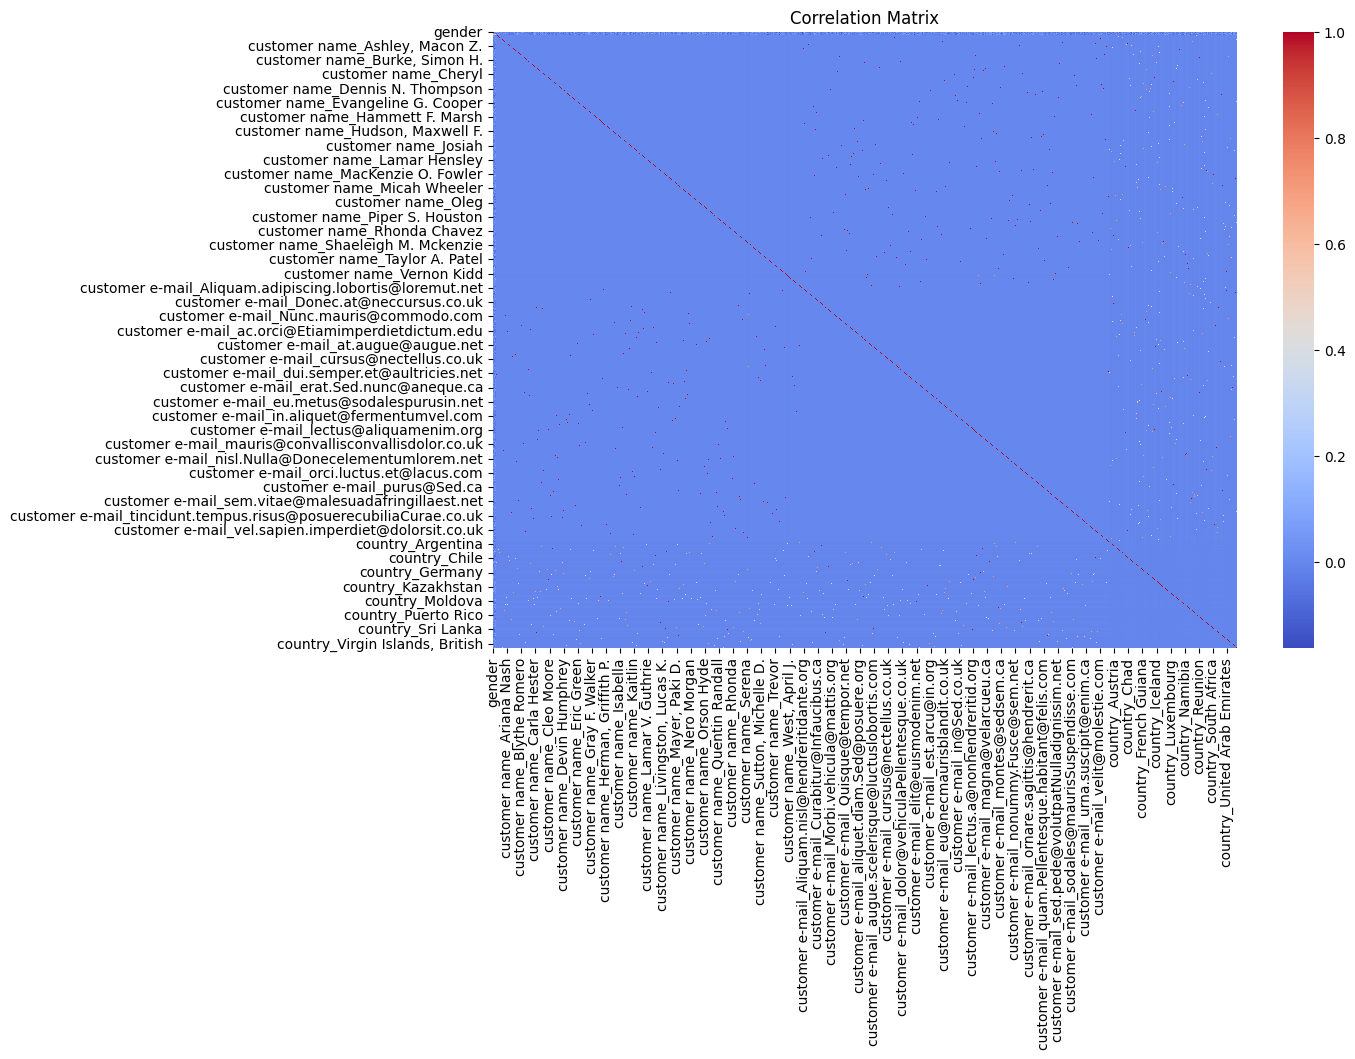

In [ ]:
# Correlation Heatmap
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 8))
sns.heatmap(correlation, annot=False, cmap='coolwarm')

plt.title("Correlation Matrix")
plt.show()

In [ ]:
#Covariance Analysis
#Covariance Matrix
covariance = df.cov(numeric_only=True)

print("Covariance Matrix:")
print(covariance)

Covariance Matrix:
                            gender           age  annual Salary  \
gender                    0.250465     -0.257480  -2.137806e+02   
age                      -0.257480     63.662233   1.217857e+01   
annual Salary          -213.780581     12.178566   1.369691e+08   
credit card debt         42.245577    966.625888   2.025378e+06   
net worth              -729.123955  28184.839646   2.999145e+07   
...                            ...           ...            ...   
country_Western Sahara   -0.002028     -0.033378   3.936946e+01   
country_Yemen            -0.001038      0.040428  -1.346433e+00   
country_Zimbabwe         -0.000024      0.002301  -5.756819e+01   
country_marlal            0.000990      0.000981  -1.516156e+00   
country_Åland Islands     0.000966     -0.013943   6.519474e+01   

                        credit card debt     net worth  car purchase amount  \
gender                      4.224558e+01 -7.291240e+02        -3.580424e+02   
age               

In [ ]:
# Train-Test Split
X = df.drop('car purchase amount', axis=1)
y = df['car purchase amount']

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (400, 1211)
Testing data: (100, 1211)


In [ ]:
#Multiple Linear Regression
#Train Linear Regression Model
from sklearn.linear_model import LinearRegression

linear_model = LinearRegression()

linear_model.fit(X_train, y_train)

LinearRegression()

In [ ]:
y_pred_linear = linear_model.predict(X_test)

In [ ]:
#Evaluate Linear Regression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae_linear = mean_absolute_error(y_test, y_pred_linear)
rmse_linear = np.sqrt(mean_squared_error(y_test, y_pred_linear))
r2_linear = r2_score(y_test, y_pred_linear)

print("Multiple Linear Regression")
print("MAE:", mae_linear)
print("RMSE:", rmse_linear)
print("R2 Score:", r2_linear)

Multiple Linear Regression
MAE: 1.2943414958325592
RMSE: 1.6419712625311633
R2 Score: 0.9999999750301868


In [ ]:
#Train Ridge Model
from sklearn.linear_model import Ridge

ridge_model = Ridge(alpha=1.0)

ridge_model.fit(X_train, y_train)

Ridge()

In [ ]:
#Ridge Predictions
y_pred_ridge = ridge_model.predict(X_test)

In [ ]:
#Evaluate Ridge Regression
mae_ridge = mean_absolute_error(y_test, y_pred_ridge)
rmse_ridge = np.sqrt(mean_squared_error(y_test, y_pred_ridge))
r2_ridge = r2_score(y_test, y_pred_ridge)

print("Ridge Regression")
print("MAE:", mae_ridge)
print("RMSE:", rmse_ridge)
print("R2 Score:", r2_ridge)

Ridge Regression
MAE: 1.422330767099993
RMSE: 1.774447345461348
R2 Score: 0.9999999708384621


In [ ]:
#Lasso Regression
# Train Lasso Model
from sklearn.linear_model import Lasso

lasso_model = Lasso(alpha=1.0)

lasso_model.fit(X_train, y_train)

Lasso()

In [ ]:
#Lasso Predictions
y_pred_lasso = lasso_model.predict(X_test)

In [ ]:
#Evaluate Lasso Regression
mae_lasso = mean_absolute_error(y_test, y_pred_lasso)
rmse_lasso = np.sqrt(mean_squared_error(y_test, y_pred_lasso))
r2_lasso = r2_score(y_test, y_pred_lasso)

print("Lasso Regression")
print("MAE:", mae_lasso)
print("RMSE:", rmse_lasso)
print("R2 Score:", r2_lasso)

Lasso Regression
MAE: 1.163321193507436
RMSE: 1.4489553408270628
R2 Score: 0.999999980555616


In [ ]:
#Decision Tree
# Train Decision Tree
from sklearn.tree import DecisionTreeRegressor

tree_model = DecisionTreeRegressor(random_state=42)

tree_model.fit(X_train, y_train)

DecisionTreeRegressor(random_state=42)

In [ ]:
#Decision Tree Predictions
y_pred_tree = tree_model.predict(X_test)

In [ ]:
#Evaluate Decision Tree
mae_tree = mean_absolute_error(y_test, y_pred_tree)
rmse_tree = np.sqrt(mean_squared_error(y_test, y_pred_tree))
r2_tree = r2_score(y_test, y_pred_tree)

print("Decision Tree Regression")
print("MAE:", mae_tree)
print("RMSE:", rmse_tree)
print("R2 Score:", r2_tree)

Decision Tree Regression
MAE: 2900.085310799999
RMSE: 3572.2495460635796
R2 Score: 0.8818135277626183


In [ ]:
#Random Forest
#Train Random Forest
from sklearn.ensemble import RandomForestRegressor

forest_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

forest_model.fit(X_train, y_train)

RandomForestRegressor(random_state=42)

In [ ]:
#Random Forest Predictions
y_pred_forest = forest_model.predict(X_test)

In [ ]:
#Evaluate Random Forest
mae_forest = mean_absolute_error(y_test, y_pred_forest)
rmse_forest = np.sqrt(mean_squared_error(y_test, y_pred_forest))
r2_forest = r2_score(y_test, y_pred_forest)

print("Random Forest Regression")
print("MAE:", mae_forest)
print("RMSE:", rmse_forest)
print("R2 Score:", r2_forest)

Random Forest Regression
MAE: 1668.0565104520024
RMSE: 2374.854375746441
R2 Score: 0.9477654138180442


In [ ]:
#Model Selection
models = {
    'Multiple Linear Regression': linear_model,
    'Ridge Regression': ridge_model,
    'Lasso Regression': lasso_model,
    'Decision Tree': tree_model,
    'Random Forest': forest_model
}

results = pd.DataFrame({
    'Model': [
        'Multiple Linear Regression',
        'Ridge Regression',
        'Lasso Regression',
        'Decision Tree',
        'Random Forest'
    ],
    'MAE': [
        mae_linear,
        mae_ridge,
        mae_lasso,
        mae_tree,
        mae_forest
    ],
    'RMSE': [
        rmse_linear,
        rmse_ridge,
        rmse_lasso,
        rmse_tree,
        rmse_forest
    ],
    'R2 Score': [
        r2_linear,
        r2_ridge,
        r2_lasso,
        r2_tree,
        r2_forest
    ]
})

results

,Model,MAE,RMSE,R2 Score
0,Multiple Linear Regression,1.294341,1.641971,1.000000
1,Ridge Regression,1.422331,1.774447,1.000000
2,Lasso Regression,1.163321,1.448955,1.000000
3,Decision Tree,2900.085311,3572.249546,0.881814
4,Random Forest,1668.056510,2374.854376,0.947765


In [ ]:
#Select Best Model
best_model_name = results.loc[results['R2 Score'].idxmax(), 'Model']

best_model = models[best_model_name]

print("Best Model:", best_model_name)

Best Model: Lasso Regression


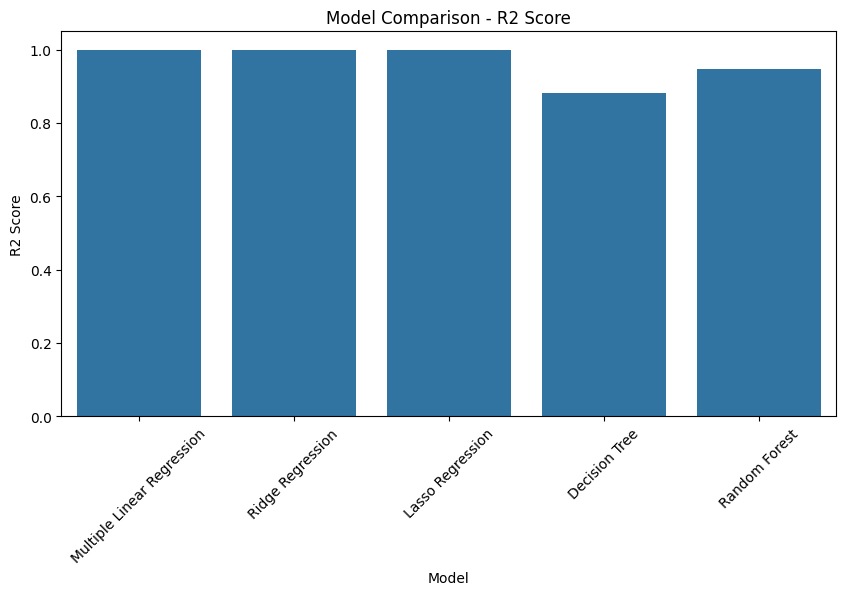

In [ ]:
#Compare R2 Scores
plt.figure(figsize=(10, 5))

sns.barplot(x='Model', y='R2 Score', data=results)

plt.xticks(rotation=45)
plt.title("Model Comparison - R2 Score")
plt.show()

In [ ]:
#Save the Best Model using Joblib
import joblib

joblib.dump(best_model, 'best_model.pkl')

print("Best model saved successfully!")

Best model saved successfully!


In [ ]:
#Load the Saved Model
loaded_model = joblib.load('best_model.pkl')

print("Model loaded successfully!")

Model loaded successfully!


In [ ]:
#Test Saved Model
predictions = loaded_model.predict(X_test)

print("First 10 Predictions:")
print(predictions[:10])

First 10 Predictions:
[46084.66655944 45060.45270934 63081.47837175 31838.16028106
 60460.87842071 63137.83247465 52479.95430251 54757.58078786
 52706.88939911 47869.38728007]
